# Fase 1 · Comprensión del problema
**Evento Evaluativo 3 · Análisis de Datos (ITM, 2026-2) · Grupo 2 · Tema: clientes bancarios**

En esta fase respondemos tres cosas: de dónde vienen los datos, qué problema de negocio queremos resolver y qué preguntas vamos a contestar. Primero miramos los datos y después decidimos, en ese orden.

## 1. Contexto: qué tipo de proyecto es

Este proyecto es de **Business Intelligence (BI)**: convertir datos en información que ayude a decidir. Se diferencia del análisis exploratorio (EDA) porque no se queda en entender los datos. Los organiza, los resume en indicadores (KPIs) y los presenta en un dashboard para quien toma decisiones.

El proyecto sigue el ciclo del BI:

| Paso del ciclo | Dónde lo hacemos |
|---|---|
| Entender el negocio | Fase 1 (este notebook) |
| Plantear hipótesis | Fase 2 |
| Preparar y modelar los datos (ETL, estrella) | Fase 3 |
| Definir indicadores (KPIs) | Fase 4 |
| Visualizar (dashboard en Power BI) | Fase 5 |
| Interpretar y proponer decisiones | Fase 6 |

## 2. Cargar los datos
El dataset es **Churn Modelling** de Kaggle. Es un dato **secundario**: alguien más lo recogió y nosotros lo reutilizamos, así que no controlamos cómo se midió.

In [1]:
import os
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
# Descarga desde Kaggle (queda en la caché de kagglehub)
ruta = kagglehub.dataset_download("shubh0799/churn-modelling")
print("Archivos descargados:", os.listdir(ruta))

Archivos descargados: ['Churn_Modelling.csv']


In [3]:
df = pd.read_csv(os.path.join(ruta, "Churn_Modelling.csv"))
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 3. Primer vistazo
Antes de decidir nada, revisamos qué tipo de dato tiene cada columna.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


**Qué significa cada columna** (esta tabla la armamos leyendo los nombres y los valores de `df.head()`):

| Columna | Qué es | Tipo |
|---|---|---|
| RowNumber | Número de fila | Identificador |
| CustomerId | Código del cliente | Identificador |
| Surname | Apellido | Identificador |
| CreditScore | Puntaje de crédito | Numérica |
| Geography | País del cliente (France, Spain, Germany) | Categórica |
| Gender | Género | Categórica |
| Age | Edad en años | Numérica |
| Tenure | Años que lleva como cliente | Numérica |
| Balance | Saldo en la cuenta | Numérica |
| NumOfProducts | Cantidad de productos del banco que tiene | Numérica (conteo) |
| HasCrCard | Tiene tarjeta de crédito (1 sí, 0 no) | Binaria |
| IsActiveMember | Es cliente activo (1 sí, 0 no) | Binaria |
| EstimatedSalary | Salario estimado | Numérica |
| **Exited** | **1 = el cliente se fue del banco, 0 = sigue** | **Variable objetivo** |

## 4. Calidad de los datos
Revisamos si hay vacíos, filas repetidas o identificadores duplicados, porque eso cambia cómo preparamos los datos en la Fase 3.

In [5]:
print("Valores nulos por columna:")
print(df.isnull().sum())
print()
print("Filas completamente duplicadas:", df.duplicated().sum())
print("CustomerId únicos:", df["CustomerId"].nunique(), "de", len(df), "filas")

Valores nulos por columna:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Filas completamente duplicadas: 0
CustomerId únicos: 10000 de 10000 filas


**Lo que se ve:** no hay nulos y no hay filas repetidas. Cada fila es un cliente distinto (cuando los `CustomerId` únicos son igual al total de filas).

**Decisión para la Fase 3:** `RowNumber`, `CustomerId` y `Surname` identifican personas pero no explican por qué se van. No los usaremos para buscar patrones. `CustomerId` sí lo dejamos como llave del cliente en el modelo de datos.

## 5. La variable objetivo: ¿cuántos clientes se van?
Como todo el proyecto gira en torno a `Exited`, miramos primero cómo se reparte.

        clientes  porcentaje
Exited                      
0           7963        79.6
1           2037        20.4


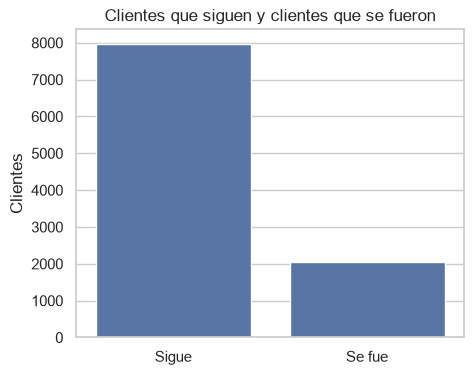

In [6]:
conteo = df["Exited"].value_counts()
porcentaje = df["Exited"].value_counts(normalize=True).mul(100).round(1)
print(pd.DataFrame({"clientes": conteo, "porcentaje": porcentaje}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Exited", ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Sigue", "Se fue"])
ax.set_xlabel("")
ax.set_ylabel("Clientes")
ax.set_title("Clientes que siguen y clientes que se fueron")
plt.show()

**Lo que se ve:** se fue cerca de **1 de cada 5 clientes (20,4 %)**. No es una cifra pequeña para un banco, porque conseguir un cliente nuevo cuesta más que mantener uno actual. Esto da el punto de partida del problema.

Como el grupo de los que se van es bastante más chico, más adelante tendremos cuidado al comparar grupos de tamaños distintos.

## 6. Problema de negocio

> **El banco pierde 1 de cada 5 clientes. ¿Qué perfil de cliente se va y qué puede hacer el banco para retenerlo?**

Lo que se busca: encontrar qué clientes están en riesgo, para que el banco enfoque sus acciones de retención en ellos, y medirlo con indicadores que se puedan seguir en un dashboard.

## 7. Preguntas clave
Cada pregunta tiene un primer vistazo. **No son conclusiones**: son pistas. En la Fase 2 las convertimos en hipótesis y las probamos con estadística.

### Pregunta 1 · ¿Cómo cambia el abandono según país, género y edad?

In [7]:
# Rangos de edad para poder comparar (se usan solo aquí; el modelo final se define en la Fase 3)
rangos = pd.cut(df["Age"], bins=[17, 30, 40, 50, 60, 100],
                labels=["18-30", "31-40", "41-50", "51-60", "60+"])

def tasa(grupo):
    t = df.groupby(grupo)["Exited"].agg(clientes="count", abandono="mean")
    t["abandono"] = (t["abandono"] * 100).round(1)
    return t

for nombre, grupo in [("País", df["Geography"]), ("Género", df["Gender"]), ("Rango de edad", rangos)]:
    print(f"--- {nombre} ---")
    print(tasa(grupo))
    print()

--- País ---
           clientes  abandono
Geography                    
France         5014      16.2
Germany        2509      32.4
Spain          2477      16.7

--- Género ---
        clientes  abandono
Gender                    
Female      4543      25.1
Male        5457      16.5

--- Rango de edad ---
       clientes  abandono
Age                      
18-30      1968       7.5
31-40      4451      12.1
41-50      2320      34.0
51-60       797      56.2
60+         464      24.8



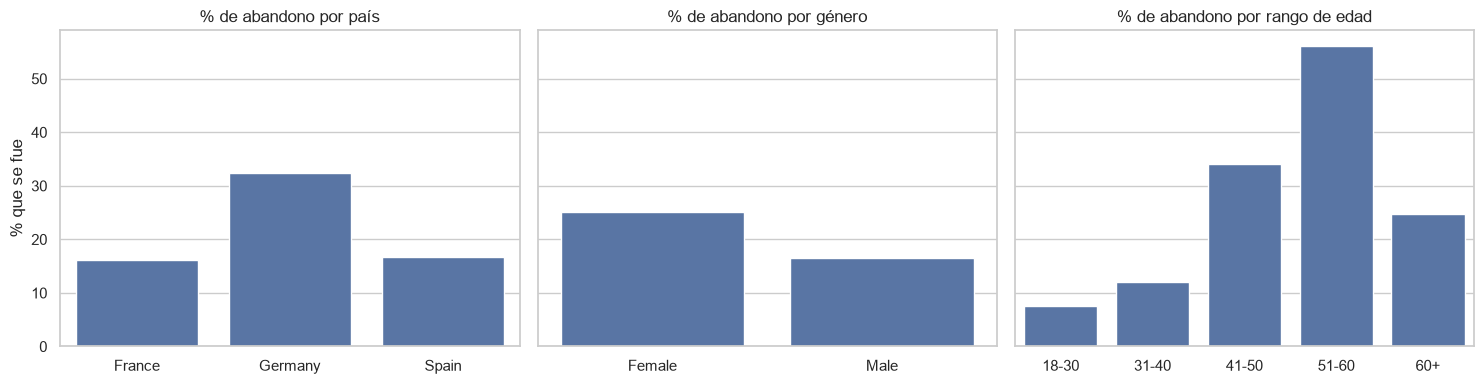

In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for eje, (nombre, grupo) in zip(ejes, [("País", df["Geography"]), ("Género", df["Gender"]), ("Rango de edad", rangos)]):
    t = tasa(grupo).reset_index()
    sns.barplot(data=t, x=t.columns[0], y="abandono", ax=eje)
    eje.set_title(f"% de abandono por {nombre.lower()}")
    eje.set_xlabel("")
    eje.set_ylabel("% que se fue")
plt.tight_layout()
plt.show()

In [9]:
print("Edad promedio de quienes siguen (0) y de quienes se fueron (1):")
print(df.groupby("Exited")["Age"].mean().round(1))

Edad promedio de quienes siguen (0) y de quienes se fueron (1):
Exited
0    37.4
1    44.8
Name: Age, dtype: float64


**Primer vistazo:** Alemania tiene casi el doble de abandono que Francia y España. Las mujeres se van más que los hombres. Los que se fueron tienen más edad en promedio (44,8 años contra 37,4); la tabla por rangos muestra desde qué edad sube el abandono.

Queda por probar si estas diferencias son reales o producto del azar (Fase 2).

### Pregunta 2 · ¿La actividad del cliente y la cantidad de productos se relacionan con que se vaya?

In [10]:
print("--- Cliente activo (1) o inactivo (0) ---")
print(tasa(df["IsActiveMember"]))
print()
print("--- Cantidad de productos ---")
print(tasa(df["NumOfProducts"]))

--- Cliente activo (1) o inactivo (0) ---
                clientes  abandono
IsActiveMember                    
0                   4849      26.9
1                   5151      14.3

--- Cantidad de productos ---
               clientes  abandono
NumOfProducts                    
1                  5084      27.7
2                  4590       7.6
3                   266      82.7
4                    60     100.0


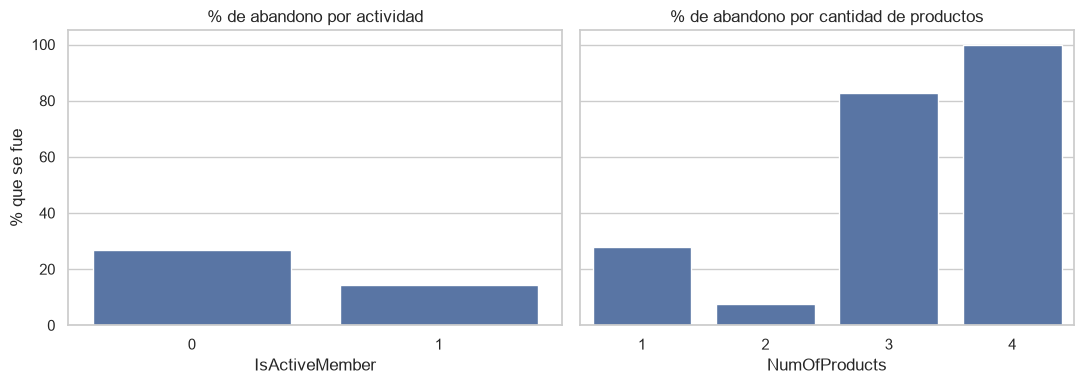

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for eje, (nombre, col) in zip(ejes, [("actividad", "IsActiveMember"), ("cantidad de productos", "NumOfProducts")]):
    t = tasa(df[col]).reset_index()
    sns.barplot(data=t, x=col, y="abandono", ax=eje)
    eje.set_title(f"% de abandono por {nombre}")
    eje.set_ylabel("% que se fue")
plt.tight_layout()
plt.show()

**Primer vistazo:** los clientes inactivos se van casi el doble que los activos (26,9 % contra 14,3 %). Con productos pasa algo distinto: quien tiene 2 productos casi no se va (7,6 %), pero quien tiene 1 se va más (27,7 %), y con 3 o 4 productos el abandono es altísimo.

**Ojo:** hay solo 266 clientes con 3 productos y 60 con 4. Son pocos para sacar conclusiones fuertes, y lo tendremos presente al interpretar.

### Pregunta 3 · ¿Qué clientes valiosos están en riesgo?
Antes de responder hay que decidir qué es un cliente "valioso". Como primera idea, usamos el **saldo**: miramos cómo se distribuye.

Clientes con saldo en cero: 36.2 %


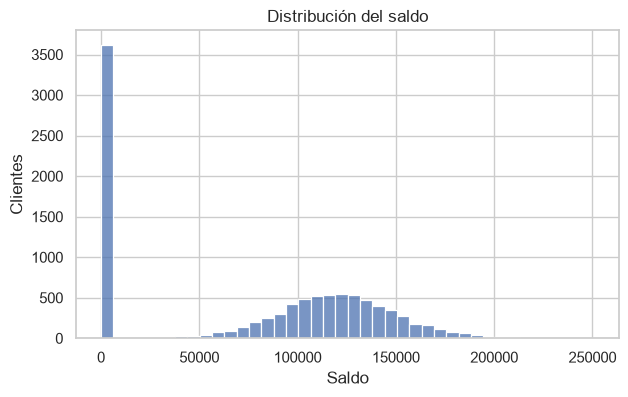

In [12]:
print("Clientes con saldo en cero:", round((df["Balance"] == 0).mean() * 100, 1), "%")

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["Balance"], bins=40, ax=ax)
ax.set_title("Distribución del saldo")
ax.set_xlabel("Saldo")
ax.set_ylabel("Clientes")
plt.show()

**Lo que se ve:** hay un grupo grande de clientes con saldo en cero, y el resto se reparte en una campana. Eso hace que el promedio de todos sirva poco como referencia.

**Decisión para esta exploración:** llamamos "cliente con saldo alto" al que está en el 25 % superior de saldo. Es una definición de trabajo; la definición final de "cliente valioso" la fijamos en la Fase 4 junto con los KPIs.

In [13]:
corte = df["Balance"].quantile(0.75)
saldo_alto = df["Balance"] > corte
print(f"Corte de saldo alto (percentil 75): {corte:,.0f}")
print()
resumen = df.groupby(saldo_alto)["Exited"].agg(clientes="count", se_fueron="sum", abandono="mean")
resumen["abandono"] = (resumen["abandono"] * 100).round(1)
resumen.index = ["Saldo no alto", "Saldo alto"]
print(resumen)

Corte de saldo alto (percentil 75): 127,644

               clientes  se_fueron  abandono
Saldo no alto      7500       1445      19.3
Saldo alto         2500        592      23.7


**Cómo leerlo:** la fila "Saldo alto" muestra cuántos clientes importantes hay y cuántos se fueron. Esto da el punto de partida para el indicador de "saldo en riesgo" de la Fase 4.

## 8. Supuestos y límites
- **Es una muestra, no todos los clientes.** Son 10.000 clientes de un banco con presencia en tres países. Lo que encontremos describe esta muestra y solo se puede generalizar con cuidado.
- **Es un dato secundario.** No sabemos cómo se recogió ni de qué fecha es, y no tenemos una columna de fecha, así que no podemos hacer análisis de tendencia en el tiempo (solo `Tenure`, que son años como cliente).
- **No sabemos por qué se fue cada cliente.** Los datos muestran con qué características se va, no la razón. Por eso hablaremos de relación y no de causa.
- **Grupos desiguales.** Hay muchos más clientes que se quedan que clientes que se van, y algunos grupos (como 3 o 4 productos) son pequeños.

## 9. Cierre de la Fase 1
| Requisito | Resultado |
|---|---|
| Contexto del dataset | Sección 2, 3 y 4 |
| Problema de negocio | Sección 6 |
| Al menos 3 preguntas clave | Sección 7 (tres preguntas con primer vistazo) |
| Límites y supuestos | Sección 8 |

**Lo que sigue:** en la Fase 2 convertimos lo que vimos en hipótesis (H0 y H1) y las probamos con t de Student y chi-cuadrado.